In [73]:
import sys

import matplotlib.pyplot as plt

sys.path = [p for p in sys.path if "positron-python" not in p]

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

import myutils

In [74]:
workspace,experiment=myutils.workspace()

In [56]:
adata = ad.read_h5ad(experiment/'data/hereos_pool7_scRNA_batches.h5ad')
adata

AnnData object with n_obs × n_vars = 10987 × 35929
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'X', 'final', 'str_batch', 'consensus_celltype'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

In [57]:
adata_hvg = adata.copy()
sc.pp.highly_variable_genes(
                adata_hvg,
                layer=None,
                n_top_genes=3000,
                batch_key=None,
                flavor="cell_ranger",
                subset=True,
            )
adata_hvg.write_h5ad(experiment/'data/hereos_pool7_scRNA_batches_hvg.h5ad')
adata_hvg

AnnData object with n_obs × n_vars = 10987 × 3000
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'X', 'final', 'str_batch', 'consensus_celltype'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

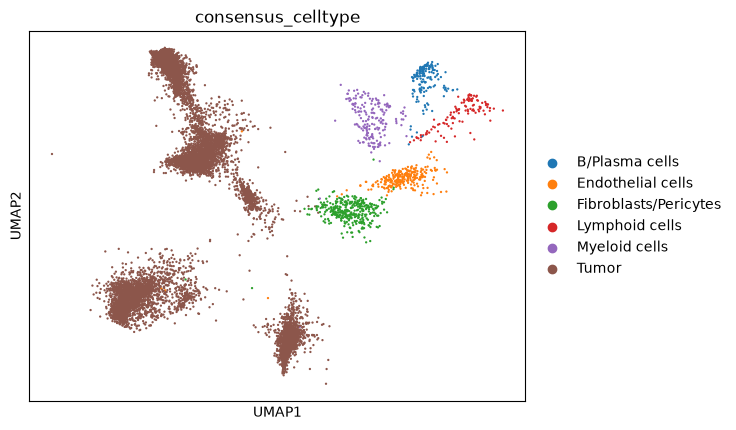

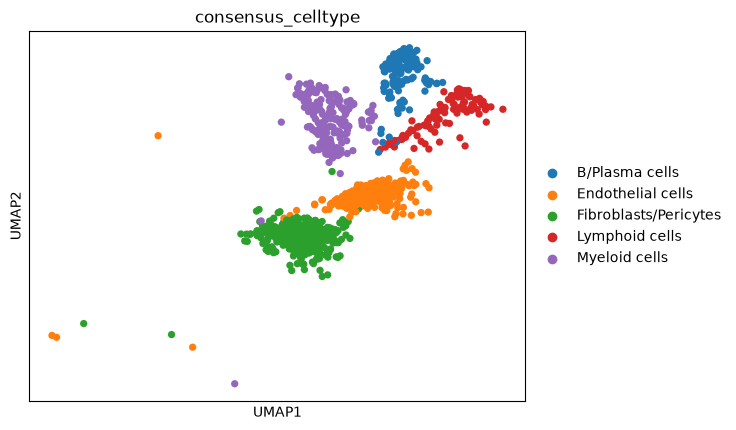

In [58]:
nask = adata.obs.consensus_celltype == "Tumor"
adata_only_tumor = adata[nask]
adata_only_nornal = adata[~(nask)]
sc.pl.umap(adata, color="consensus_celltype")
sc.pl.umap(adata_only_nornal, color="consensus_celltype")

2077


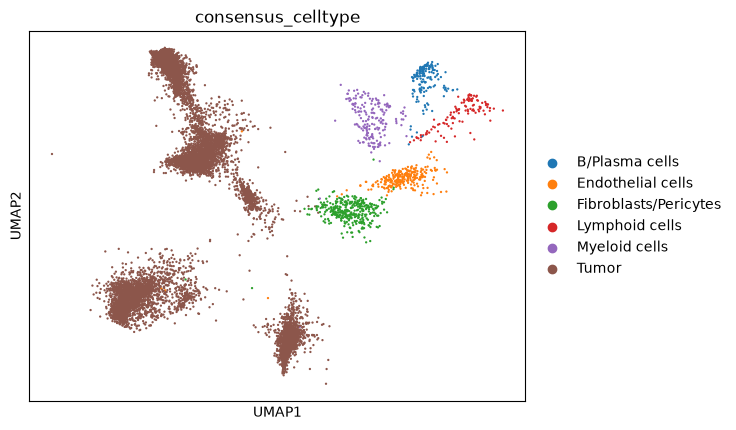

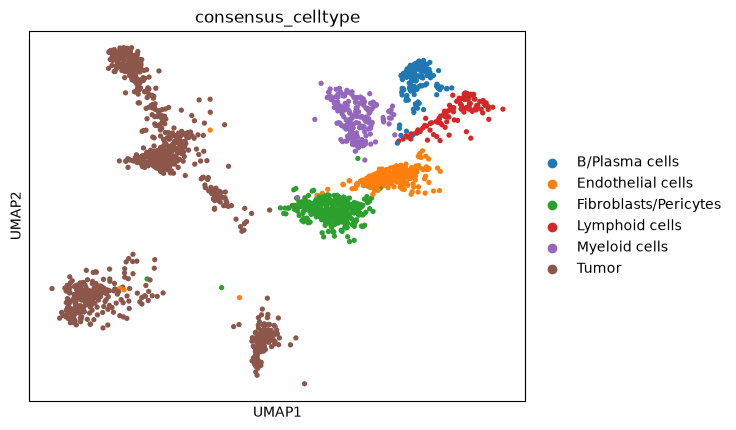

In [59]:
np.random.seed(42)

n_cells = int(adata_only_tumor.n_obs * 0.1)
selected_idx = np.random.choice(adata_only_tumor.n_obs, n_cells, replace=False)
tumor_cell_selection = adata_only_tumor.obs_names[selected_idx]
normal_cell_selection = adata_only_nornal.obs_names
cells = list(set(tumor_cell_selection) | set(normal_cell_selection))
adata_small_tumor = adata[adata.obs.index.isin(cells)]
print(len(cells))
sc.pl.umap(adata, color="consensus_celltype")
sc.pl.umap(adata_small_tumor, color="consensus_celltype")

In [60]:
print(sum(adata.obs.str_batch == '0') / adata.n_obs, sum(adata.obs.str_batch == '1') / adata.n_obs)
print(sum(adata.obs.str_batch == '0'),sum(adata.obs.str_batch == '1'))

0.2999908983343952 0.7000091016656048
3296 7691


In [29]:
print(sum(adata_only_nornal.obs.str_batch == '0') / adata_only_nornal.n_obs, sum(adata_only_nornal.obs.str_batch == '1') / adata_only_nornal.n_obs)
print(sum(adata_only_nornal.obs.str_batch == '0'),sum(adata_only_nornal.obs.str_batch == '1'))

0.30514705882352944 0.6948529411764706
332 756


In [30]:
print(sum(adata_small_tumor.obs.str_batch == '0') / adata_small_tumor.n_obs, sum(adata_small_tumor.obs.str_batch == '1') / adata_small_tumor.n_obs)
print(sum(adata_small_tumor.obs.str_batch == '0'),sum(adata_small_tumor.obs.str_batch == '1'))

0.30765527202696197 0.692344727973038
639 1438


In [61]:
adata_small_tumor

View of AnnData object with n_obs × n_vars = 2077 × 35929
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'X', 'final', 'str_batch', 'consensus_celltype'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'consensus_celltype_colors'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

In [62]:
adata_only_nornal

AnnData object with n_obs × n_vars = 1088 × 35929
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'X', 'final', 'str_batch', 'consensus_celltype'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'consensus_celltype_colors'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

In [63]:
adata_only_nornal.write_h5ad(experiment/'data/hereos_pool7_scRNA_batches_only_normal.h5ad')
adata_only_nornal

AnnData object with n_obs × n_vars = 1088 × 35929
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'X', 'final', 'str_batch', 'consensus_celltype'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'consensus_celltype_colors'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

In [64]:
adata_small_tumor.write_h5ad(experiment/'data/hereos_pool7_scRNA_batches_small_tumor.h5ad')
adata_small_tumor

View of AnnData object with n_obs × n_vars = 2077 × 35929
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'X', 'final', 'str_batch', 'consensus_celltype'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'consensus_celltype_colors'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)

In [65]:
adata_hvg = adata.copy()
sc.pp.highly_variable_genes(
                adata_hvg,
                layer=None,
                n_top_genes=None,
                batch_key=None,
                flavor='cell_ranger',
                subset=True,
            )
adata_hvg

AnnData object with n_obs × n_vars = 10987 × 5454
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'X', 'final', 'str_batch', 'consensus_celltype'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'consensus_celltype_colors', 'hvg'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    obsp: 'connectivities', 'distances'
    layers: None (.X)